In [1]:
# === Imports & global configuration ===

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Boosting models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Preprocessing & evaluation
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt


## Load input datasets

In [2]:
# === Imports & global configuration ===

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Boosting models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Preprocessing & evaluation
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

In [28]:
# === Load input datasets ===

DATA_DIR = Path("data/processed")
scores_path = DATA_DIR / "20190108_scores_and_weak_links.csv"
big_path = DATA_DIR / "AimoScore_WeakLink_big_scores.csv"

scores = pd.read_csv(scores_path)
big = pd.read_csv(big_path)

print(scores.shape, big.shape)
print(scores.columns[:10])
print(big.columns[:10])


(2096, 17) (2094, 43)
Index(['ID', 'Date', 'SCORE', 'ForwardHead', 'LeftArmFallForward',
       'RightArmFallForward', 'LeftShoulderElevation',
       'RightShoulderElevation', 'ExcessiveForwardLean',
       'LeftAsymmetricalWeightShift'],
      dtype='object')
Index(['AimoScore', 'No_1_Angle_Deviation', 'No_2_Angle_Deviation',
       'No_3_Angle_Deviation', 'No_4_Angle_Deviation', 'No_5_Angle_Deviation',
       'No_6_Angle_Deviation', 'No_7_Angle_Deviation', 'No_8_Angle_Deviation',
       'No_9_Angle_Deviation'],
      dtype='object')


## Create WeakestLink labels (rule-based)

In [29]:
# === Create WeakestLink labels ===

NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightAsymmetricalWeightShift"
}

indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]


scores[indicator_cols] = scores[indicator_cols].apply(
    pd.to_numeric, errors="coerce"
)

row_max = scores[indicator_cols].max(axis=1)
ties = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)
scores["HasTie"] = ties

print("Tie rows:", int(scores["HasTie"].sum()))
print("Label null rows:", int(scores["WeakestLink"].isna().sum()))


Tie rows: 372
Label null rows: 0


## Merge labels with feature dataset

In [30]:
# === Merge labels with features ===

labels = scores[["ID", "WeakestLink", "HasTie"]].dropna()
data = big.merge(labels, on="ID", how="inner")

print("After merge:", data.shape)
print("Unique classes:", data["WeakestLink"].nunique())


After merge: (2094, 45)
Unique classes: 10


## Feature selection & cleaning

In [31]:
# === Feature selection & cleaning ===

angle_cols = [f"No_{i}_Angle_Deviation" for i in range(1, 14)]
nasm_cols = [f"No_{i}_NASM_Deviation" for i in range(1, 26)]
feature_cols = angle_cols + nasm_cols

X = data[feature_cols].apply(pd.to_numeric, errors="coerce")
y = data["WeakestLink"].astype(str)

mask = X.notna().all(axis=1)
X, y = X[mask], y[mask]

print("After dropping NaNs:", X.shape, y.shape)


After dropping NaNs: (2094, 38) (2094,)


## Handle ties & singleton classes

In [32]:
# === Handle ties & singleton classes ===

has_tie = data.loc[X.index, "HasTie"].astype(bool)

X_keep, y_keep = X.copy(), y.copy()
X_notie, y_notie = X.loc[~has_tie], y.loc[~has_tie]

counts = y_keep.value_counts()
singletons = counts[counts < 2].index

X2 = X_keep[~y_keep.isin(singletons)]
y2 = y_keep[~y_keep.isin(singletons)]

print("Final dataset:", X2.shape)
print("Smallest class count:", y2.value_counts().min())


Final dataset: (2094, 38)
Smallest class count: 46


## Train/test split & cross-validation setup

In [33]:
# === Train/test split & cross-validation ===

X_train, X_test, y_train, y_test = train_test_split(
    X2, y2,
    test_size=0.2,
    random_state=42,
    stratify=y2
)

min_class = y_train.value_counts().min()
cv_splits = max(2, min(5, min_class))

cv = StratifiedKFold(
    n_splits=cv_splits,
    shuffle=True,
    random_state=42
)

print("Using cv_splits =", cv_splits)


Using cv_splits = 5


## Label encoding (boosting models only)

In [34]:
# === Label encoding (boosting models only) ===

label_encoder = LabelEncoder()
y2_encoded = label_encoder.fit_transform(y2)

class_names = list(label_encoder.classes_)

X_train_enc, X_test_enc, y_train_enc, y_test_enc = train_test_split(
    X2, y2_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y2_encoded
)


## Model definitions

In [35]:
# === Model definitions ===
models = {
    "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),

    "logreg_C1_balanced": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            C=1.0
        ))
    ]),
    "logreg_C0.3_balanced": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            C=0.3
        ))
    ]),

    "gaussian_nb": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", GaussianNB())
    ]),

    "lda": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis())
    ]),

    # stable shrinkage LDA variant
    "lda_lsqr_shrinkage_auto": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    ]),

    "knn_k5": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
    "knn_k15": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15))
    ]),
    "xgboost": Pipeline([
        ("clf", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            eval_metric="mlogloss",
            num_class=len(class_names),
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "lightgbm": Pipeline([
        ("clf", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "catboost": Pipeline([
    ("clf", CatBoostClassifier(
        iterations=300,
        learning_rate=0.1,
        depth=6,
        loss_function="MultiClass",
        auto_class_weights="Balanced",
        verbose=False,
        random_seed=42,
        train_dir="catboost_tmp"
    ))
]),
}


## Cross-validation comparison

In [36]:
# ============================================================
# === Cross-validation comparison (with run metadata) ===
# Adds columns to results_df so you can see (and screenshot):
# - dataset tag (optional)
# - number of folds (cv_splits)
# - which WeakestLink classes were removed (or None)
# ============================================================

from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

# Optional label to identify this run in screenshots
DATASET_TAG = globals().get("DATASET_TAG", "dataset variant not specified")

# WeakestLink removal info (handles "no dropped weakest link" cleanly)
if "DROP_WEAK_LINKS" in globals() and DROP_WEAK_LINKS:
    removed_links_sorted = sorted(list(DROP_WEAK_LINKS))
    removed_links_str = ", ".join(removed_links_sorted)
else:
    removed_links_str = "None"

# Pull fold count from your earlier logic (or fallback to cv.n_splits if present)
cv_folds = globals().get("cv_splits", getattr(cv, "n_splits", "unknown"))

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

rows = []

for name, model in models.items():

    # Use encoded labels ONLY for XGBoost (as in your notebook)
    if name == "xgboost":
        Xtr, ytr = X_train_enc, y_train_enc
    else:
        Xtr, ytr = X_train, y_train

    out = cross_validate(
        model,
        Xtr, ytr,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {
        "dataset_tag": DATASET_TAG,
        "cv_folds": cv_folds,
        "removed_weakest_links": removed_links_str,
        "model": name,
    }

    for m in scoring:
        row[f"{m}_mean"] = float(np.mean(out[f"test_{m}"]))

    rows.append(row)

results_df = (
    pd.DataFrame(rows)
    .sort_values("f1_macro_mean", ascending=False)
    .reset_index(drop=True)
)

results_df


,dataset_tag,cv_folds,removed_weakest_links,model,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_weighted_mean
0,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",lightgbm,0.626866,0.614591,0.538445,0.546801,0.620211
1,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",xgboost,0.626269,0.589163,0.516456,0.530201,0.616939
2,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",logreg_C1_balanced,0.533731,0.464268,0.562703,0.483404,0.544754
3,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",lda,0.581493,0.494483,0.485294,0.482724,0.578717
4,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",logreg_C0.3_balanced,0.524179,0.456015,0.560016,0.473350,0.536068
5,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",lda_lsqr_shrinkage_auto,0.560597,0.479618,0.474330,0.469060,0.558079
6,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",knn_k5,0.538507,0.532662,0.432321,0.456589,0.532966
7,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",gaussian_nb,0.450149,0.399227,0.458256,0.404265,0.462902
8,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",knn_k15,0.533731,0.454105,0.373375,0.388497,0.515144
9,dataset variant not specified,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",dummy_most_frequent,0.303881,0.030388,0.100000,0.046612,0.141645


## Train final champion model

In [37]:
# === Train final champion model ===

best_name = results_df.iloc[0]["model"]
best_model = models[best_name]

if best_name == "xgboost":
    best_model.fit(X_train_enc, y_train_enc)
    pred_enc = best_model.predict(X_test_enc)
    y_pred = label_encoder.inverse_transform(pred_enc)
else:
    best_model.fit(X_train, y_train)
    y_pred = best_model.predict(X_test)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000967 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9687
[LightGBM] [Info] Number of data points in the train set: 1675, number of used features: 38
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] N

## Save final champion model

In [52]:
# === Save the champion model + metadata ===

import json
import joblib
from pathlib import Path

OUT_MODEL_DIR = Path("..") / "trained_models/weakest_link_model"
OUT_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save model
joblib.dump(best_model, OUT_MODEL_DIR / "champion_model.joblib")

# Save label encoder too (ONLY needed for xgboost in this notebook)
if best_name == "xgboost":
    joblib.dump(label_encoder, OUT_MODEL_DIR / "label_encoder.joblib")

# Save metadata needed for correct inference later
meta = {
    "feature_cols": feature_cols,
    "model_name": best_name,
    "classes": (
        class_names if ("class_names" in globals()) else sorted(y2.unique().tolist())
    ),
    "cv_splits": cv_splits,
    "dropped_weakest_links": (
        sorted(list(DROP_WEAK_LINKS)) if ("DROP_WEAK_LINKS" in globals()) else []
    ),
    "uses_label_encoder": (best_name == "xgboost"),
}

(OUT_MODEL_DIR / "champion_meta.json").write_text(json.dumps(meta, indent=2))
print("Saved model + meta to:", OUT_MODEL_DIR)


Saved model + meta to: ..\trained_models\weakest_link_model


## Load the trained model + test with 38 feature values

#### Test 1

In [57]:
example_38_a = [
    0.364418938, 0.269249163, 0.665231946, 0.599234816, 0.69010043,
    0.565758011, 0.462936394, 0.521759923, 0.899569584, 0.989478718,
    0.635581062, 0.81252989,  0.762314682, 0.69010043,  0.462936394,
    0.364418938, 0.989478718, 0.762314682, 0.735054998, 0.736011478,
    0.511716882, 0.245815399, 0.286465806, 0.864658058, 0.618842659,
    0.544715447, 0.978000956, 0.728837877, 0.853658537, 0.772357724,
    0.441415591, 0.865136298, 0.656623625, 0.642276423, 0.552845528,
    0.648971784, 0.949306552, 0.308943089
]

pred, top = predict_weakest_link(example_38_a, top_k=5)
print("Predicted WeakestLink:", pred)
if top:
    print("Top probabilities:")
    for cls, p in top:
        print(f"  {cls:30s} {p:.3f}")


Predicted WeakestLink: LeftArmFallForward
Top probabilities:
  LeftArmFallForward             0.999
  RightArmFallForward            0.000
  RightShoulderElevation         0.000
  RightKneeMovesOutward          0.000
  LeftShoulderElevation          0.000


#### Test 2

In [58]:
example_38_b = [
    0.958871353, 0.979913917, 0.494978479, 0.706838833, 0.334289813,
    0.140124342, 0.408417025, 0.521759923, 0.741272119, 0.754184601,
    0.635581062, 0.528933525, 0.74796748,  0.334289813, 0.408417025,
    0.958871353, 0.754184601, 0.74796748,  0.599713056, 0.986131038,
    0.093830703, 0.890961263, 0.809182209, 0.409373505, 0.321377331,
    0.654710665, 0.603538977, 0.459110473, 0.411286466, 0.661884266,
    0.594452415, 0.74988044,  0.656623625, 0.642276423, 0.708273553,
    0.648971784, 0.578192253, 0.785270206
]

pred, top = predict_weakest_link(example_38_b, top_k=5)
print("Predicted WeakestLink:", pred)
if top:
    print("Top probabilities:")
    for cls, p in top:
        print(f"  {cls:30s} {p:.3f}")


Predicted WeakestLink: ForwardHead
Top probabilities:
  ForwardHead                    1.000
  RightArmFallForward            0.000
  LeftArmFallForward             0.000
  LeftShoulderElevation          0.000
  RightShoulderElevation         0.000


## Overall classification report

In [134]:
# === Per-class F1 scores ===

per_class_f1 = f1_score(
    y_test,
    y_pred,
    average=None,
    labels=class_names,
    zero_division=0
)

per_class_f1_df = pd.DataFrame({
    "class": class_names,
    "f1_score": per_class_f1
}).sort_values("f1_score")

per_class_f1_df


,class,f1_score
7,RightKneeMovesInward,0.153846
5,LeftShoulderElevation,0.235294
4,LeftKneeMovesOutward,0.285714
3,LeftAsymmetricalWeightShift,0.466667
0,ExcessiveForwardLean,0.558140
9,RightShoulderElevation,0.565657
6,RightArmFallForward,0.600985
1,ForwardHead,0.619048
2,LeftArmFallForward,0.646154
8,RightKneeMovesOutward,0.890909


## Confusion matrix

In [39]:
# === Confusion matrix ===

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_names
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df


,ExcessiveForwardLean,ForwardHead,LeftArmFallForward,LeftAsymmetricalWeightShift,LeftKneeMovesOutward,LeftShoulderElevation,RightArmFallForward,RightKneeMovesInward,RightKneeMovesOutward,RightShoulderElevation
ExcessiveForwardLean,12,1,3,0,0,1,2,0,0,2
ForwardHead,2,13,3,1,0,0,3,0,1,1
LeftArmFallForward,2,0,84,2,1,2,28,1,3,4
LeftAsymmetricalWeightShift,2,1,0,7,0,0,4,1,0,0
LeftKneeMovesOutward,0,0,3,0,3,0,2,0,1,1
LeftShoulderElevation,0,0,2,0,2,2,0,0,0,5
RightArmFallForward,1,2,25,0,2,0,61,0,0,4
RightKneeMovesInward,0,0,5,0,0,1,0,1,0,2
RightKneeMovesOutward,1,0,3,0,0,0,1,1,49,1
RightShoulderElevation,2,1,5,5,3,0,7,0,0,28


## Confusion matrix visualization

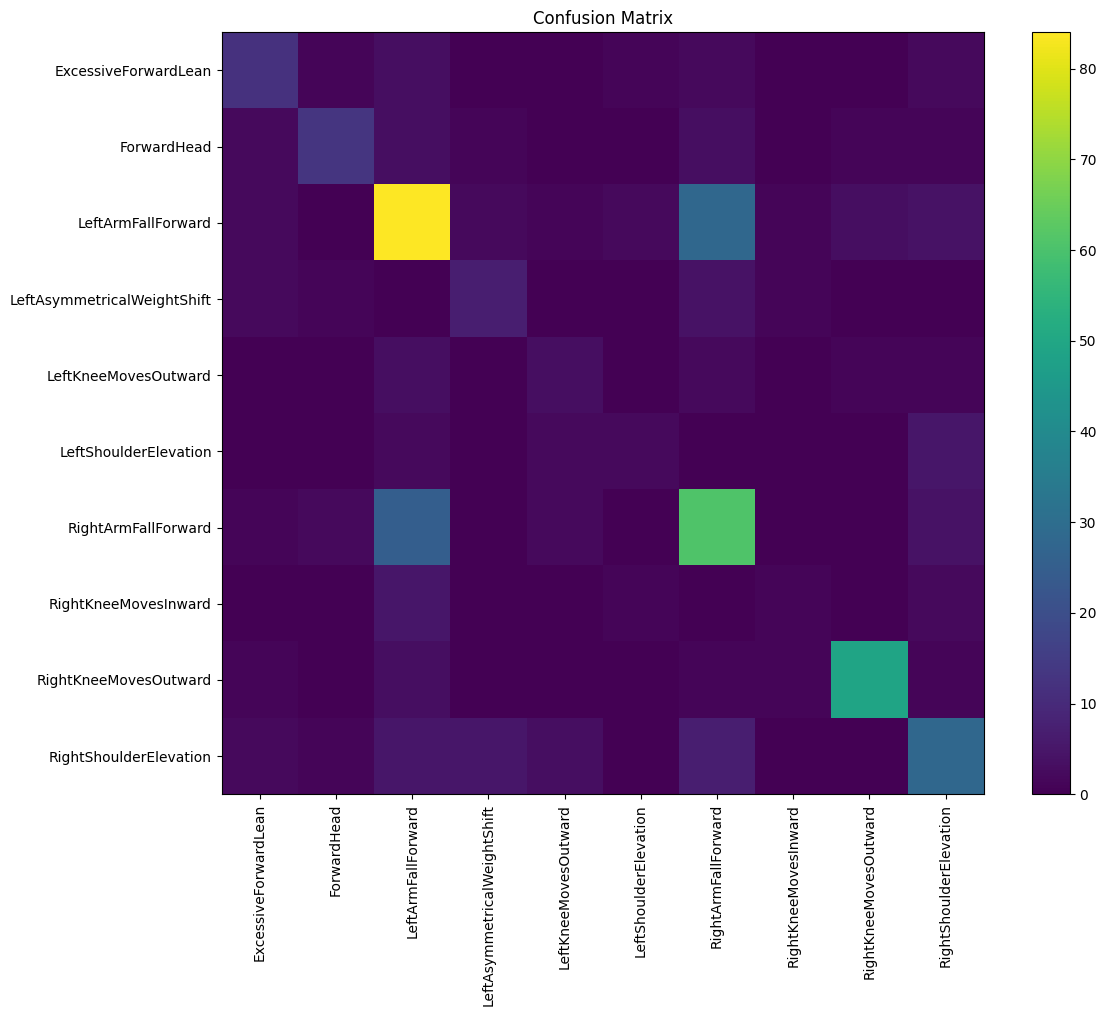

In [40]:
# === Confusion matrix visualization ===

plt.figure(figsize=(12, 10))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks(range(len(class_names)), class_names, rotation=90)
plt.yticks(range(len(class_names)), class_names)

plt.tight_layout()
plt.show()


In [41]:
# === Number of classes seen during training ===

n_classes_total = y2.nunique()
n_classes_train = y_train.nunique()
n_classes_test = y_test.nunique()

print(f"Total classes in dataset: {n_classes_total}")
print(f"Classes present in training set: {n_classes_train}")
print(f"Classes present in test set: {n_classes_test}")


Total classes in dataset: 10
Classes present in training set: 10
Classes present in test set: 10


In [42]:
# === Class coverage: full dataset vs train vs test ===

coverage_df = pd.DataFrame({
    "full_dataset": y2.value_counts(),
    "training_set": y_train.value_counts(),
    "test_set": y_test.value_counts(),
}).fillna(0).astype(int)

coverage_df["present_in_train"] = coverage_df["training_set"] > 0
coverage_df["present_in_test"] = coverage_df["test_set"] > 0

coverage_df.sort_values("full_dataset")


,full_dataset,training_set,test_set,present_in_train,present_in_test
WeakestLink,,,,,
RightKneeMovesInward,46,37,9,True,True
LeftKneeMovesOutward,50,40,10,True,True
LeftShoulderElevation,58,47,11,True,True
LeftAsymmetricalWeightShift,73,58,15,True,True
ExcessiveForwardLean,105,84,21,True,True
ForwardHead,118,94,24,True,True
RightShoulderElevation,256,205,51,True,True
RightKneeMovesOutward,278,222,56,True,True
RightArmFallForward,474,379,95,True,True


In [43]:
# === Per-class F1 score with train/test support ===

from sklearn.metrics import f1_score

per_class_f1 = f1_score(
    y_test,
    y_pred,
    labels=coverage_df.index,
    average=None,
    zero_division=0
)

f1_analysis_df = coverage_df.copy()
f1_analysis_df["f1_score"] = per_class_f1

f1_analysis_df = f1_analysis_df.sort_values("training_set")

f1_analysis_df


,full_dataset,training_set,test_set,present_in_train,present_in_test,f1_score
WeakestLink,,,,,,
RightKneeMovesInward,46,37,9,True,True,0.153846
LeftKneeMovesOutward,50,40,10,True,True,0.285714
LeftShoulderElevation,58,47,11,True,True,0.235294
LeftAsymmetricalWeightShift,73,58,15,True,True,0.466667
ExcessiveForwardLean,105,84,21,True,True,0.558140
ForwardHead,118,94,24,True,True,0.619048
RightShoulderElevation,256,205,51,True,True,0.565657
RightKneeMovesOutward,278,222,56,True,True,0.890909
RightArmFallForward,474,379,95,True,True,0.600985


## NO-TIE TRAINING EXPERIMENT

In [30]:
# ============================================================
# NO-TIE TRAINING EXPERIMENT (drop rows where WeakestLink had ties)
# This cell assumes you already created:
#   - data (merged dataframe that includes "HasTie")
#   - X, y (after NaN-drop on features)
#   - feature_cols (list of 38 features)
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# If you want boosting here too, keep these imports (optional)
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# -----------------------
# 1) Build the NO-TIE dataset
# -----------------------
# IMPORTANT: X.index is aligned with data.loc[X.index] because X was created from data after merge
has_tie = data.loc[X.index, "HasTie"].astype(bool)

X_nt = X.loc[~has_tie].copy()
y_nt = y.loc[~has_tie].copy()

print("No-tie dataset shape:", X_nt.shape, y_nt.shape)
print("Unique classes (no-tie):", y_nt.nunique())

# Drop singleton classes again (classes with < 2 samples cannot be stratified reliably)
counts_nt = y_nt.value_counts()
singletons_nt = counts_nt[counts_nt < 2].index.tolist()

print("Singleton classes in no-tie dataset:", singletons_nt)

keep_nt = ~y_nt.isin(singletons_nt)
X2_nt = X_nt.loc[keep_nt].copy()
y2_nt = y_nt.loc[keep_nt].copy()

print("After dropping singletons (no-tie):", X2_nt.shape, y2_nt.shape)
print("Smallest class count (no-tie):", int(y2_nt.value_counts().min()))


# -----------------------
# 2) Train/test split (80/20) on no-tie data
# -----------------------
X_train_nt, X_test_nt, y_train_nt, y_test_nt = train_test_split(
    X2_nt, y2_nt,
    test_size=0.2,
    random_state=42,
    stratify=y2_nt
)

print("\nTrain size:", X_train_nt.shape, "Test size:", X_test_nt.shape)
print("Train smallest class count:", int(y_train_nt.value_counts().min()))
print("Test smallest class count:", int(y_test_nt.value_counts().min()))


# -----------------------
# 3) CV setup (robust for small classes)
# -----------------------
min_class_nt = y_train_nt.value_counts().min()
cv_splits_nt = max(2, min(5, int(min_class_nt)))  # <= smallest class count, at least 2
cv_nt = StratifiedKFold(n_splits=cv_splits_nt, shuffle=True, random_state=42)

print("\nUsing cv_splits_nt =", cv_splits_nt, "because min_class_nt =", int(min_class_nt))


# -----------------------
# 4) Define models (same set as before, plus boosting if desired)
# -----------------------
models_nt = {
    "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),

    "logreg_C1_balanced": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            C=1.0
        ))
    ]),
    "logreg_C0.3_balanced": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            C=0.3
        ))
    ]),

    "gaussian_nb": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", GaussianNB())
    ]),

    "lda": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis())
    ]),

    "lda_lsqr_shrinkage_auto": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    ]),

    "knn_k5": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
    "knn_k15": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15))
    ]),
}

# OPTIONAL: include boosting models on the no-tie split
# XGBoost requires integer labels in many setups
label_encoder_nt = LabelEncoder()
y2_nt_encoded = label_encoder_nt.fit_transform(y2_nt)
class_names_nt = list(label_encoder_nt.classes_)

X_train_nt_enc, X_test_nt_enc, y_train_nt_enc, y_test_nt_enc = train_test_split(
    X2_nt, y2_nt_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y2_nt_encoded
)

models_nt.update({
    "xgboost": Pipeline([
        ("clf", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            eval_metric="mlogloss",
            num_class=len(class_names_nt),
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "lightgbm": Pipeline([
        ("clf", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "catboost": Pipeline([
        ("clf", CatBoostClassifier(
            iterations=300,
            learning_rate=0.1,
            depth=6,
            loss_function="MultiClass",
            auto_class_weights="Balanced",
            verbose=False,
            random_seed=42,
            # prevents CatBoost from trying to create a working directory like "catboost_info"
            allow_writing_files=False
        ))
    ]),
})


# -----------------------
# 5) Cross-validated comparison on no-tie training set
# -----------------------
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

rows = []
print("\n=== NO-TIE CV RESULTS (mean ± standard deviation) ===")

for name, model in models_nt.items():

    # Use encoded labels ONLY for XGBoost
    if name == "xgboost":
        Xtr, ytr = X_train_nt_enc, y_train_nt_enc
    else:
        Xtr, ytr = X_train_nt, y_train_nt

    out = cross_validate(
        model,
        Xtr, ytr,
        cv=cv_nt,
        scoring=scoring,
        n_jobs=-1,
        error_score=np.nan,
        return_train_score=False
    )

    row = {"model": name}
    for m in scoring:
        row[f"{m}_mean"] = float(np.nanmean(out[f"test_{m}"]))
        row[f"{m}_std"] = float(np.nanstd(out[f"test_{m}"]))
    rows.append(row)

    print(
        f"{name:26s} | "
        f"Acc {row['accuracy_mean']:.3f} | "
        f"P(m) {row['precision_macro_mean']:.3f} | "
        f"R(m) {row['recall_macro_mean']:.3f} | "
        f"F1(m) {row['f1_macro_mean']:.3f} | "
        f"F1(w) {row['f1_weighted_mean']:.3f}"
    )

results_nt_df = (
    pd.DataFrame(rows)
    .sort_values("f1_macro_mean", ascending=False)
    .reset_index(drop=True)
)

print("\nTop models on no-tie CV (sorted by macro-F1):")
display(results_nt_df)


# -----------------------
# 6) Pick champion (by CV macro-F1) and evaluate on no-tie test set
# -----------------------
best_name_nt = results_nt_df.loc[0, "model"]
best_model_nt = models_nt[best_name_nt]

print("\n=== NO-TIE CHAMPION (by CV macro-F1) ===")
print("Champion:", best_name_nt)

if best_name_nt == "xgboost":
    # Fit using encoded labels
    best_model_nt.fit(X_train_nt_enc, y_train_nt_enc)
    y_pred_enc = best_model_nt.predict(X_test_nt_enc)

    # Decode back to original class names for readable reporting
    y_pred_nt = label_encoder_nt.inverse_transform(y_pred_enc.astype(int))
    y_true_nt = label_encoder_nt.inverse_transform(y_test_nt_enc.astype(int))
else:
    best_model_nt.fit(X_train_nt, y_train_nt)
    y_pred_nt = best_model_nt.predict(X_test_nt)
    y_true_nt = y_test_nt

test_metrics_nt = {
    "accuracy": accuracy_score(y_true_nt, y_pred_nt),
    "precision_macro": precision_score(y_true_nt, y_pred_nt, average="macro", zero_division=0),
    "recall_macro": recall_score(y_true_nt, y_pred_nt, average="macro", zero_division=0),
    "f1_macro": f1_score(y_true_nt, y_pred_nt, average="macro", zero_division=0),
    "f1_weighted": f1_score(y_true_nt, y_pred_nt, average="weighted", zero_division=0),
}

print("\n=== NO-TIE TEST METRICS ===")
print(test_metrics_nt)

print("\n=== NO-TIE CLASSIFICATION REPORT (per-class precision/recall/F1/support) ===")
print(classification_report(y_true_nt, y_pred_nt, zero_division=0))


# -----------------------
# 7) Confusion matrix (no-tie test set)
# -----------------------
labels_sorted = sorted(pd.unique(y_true_nt))
cm = confusion_matrix(y_true_nt, y_pred_nt, labels=labels_sorted)
cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)

print("\n=== NO-TIE CONFUSION MATRIX (rows=true, cols=pred) ===")
display(cm_df)


# -----------------------
# 8) Per-class F1 score + class coverage (full / train / test)
# -----------------------
coverage_full = y2_nt.value_counts().rename("full_dataset")
coverage_train = pd.Series(y_train_nt).value_counts().rename("training_set")
coverage_test = pd.Series(y_true_nt).value_counts().rename("test_set")

coverage_df = pd.concat([coverage_full, coverage_train, coverage_test], axis=1).fillna(0).astype(int)
coverage_df["present_in_train"] = coverage_df["training_set"] > 0
coverage_df["present_in_test"] = coverage_df["test_set"] > 0

per_class_f1 = f1_score(
    y_true_nt,
    y_pred_nt,
    labels=coverage_df.index,
    average=None,
    zero_division=0
)

f1_analysis_df = coverage_df.copy()
f1_analysis_df["f1_score"] = per_class_f1
f1_analysis_df = f1_analysis_df.sort_values(["training_set", "test_set", "full_dataset"])

print("\n=== NO-TIE PER-CLASS F1 + SUPPORT (full/train/test) ===")
display(f1_analysis_df)


No-tie dataset shape: (1717, 38) (1717,)
Unique classes (no-tie): 14
Singleton classes in no-tie dataset: ['RightHeelRises']
After dropping singletons (no-tie): (1716, 38) (1716,)
Smallest class count (no-tie): 2

Train size: (1372, 38) Test size: (344, 38)
Train smallest class count: 2
Test smallest class count: 1

Using cv_splits_nt = 2 because min_class_nt = 2

=== NO-TIE CV RESULTS (mean ± standard deviation) ===
dummy_most_frequent        | Acc 0.263 | P(m) 0.020 | R(m) 0.077 | F1(m) 0.032 | F1(w) 0.110
logreg_C1_balanced         | Acc 0.507 | P(m) 0.343 | R(m) 0.399 | F1(m) 0.354 | F1(w) 0.516
logreg_C0.3_balanced       | Acc 0.495 | P(m) 0.342 | R(m) 0.404 | F1(m) 0.353 | F1(w) 0.505
gaussian_nb                | Acc 0.463 | P(m) 0.324 | R(m) 0.360 | F1(m) 0.326 | F1(w) 0.474
lda                        | Acc 0.561 | P(m) 0.384 | R(m) 0.379 | F1(m) 0.375 | F1(w) 0.557
lda_lsqr_shrinkage_auto    | Acc 0.555 | P(m) 0.374 | R(m) 0.376 | F1(m) 0.371 | F1(w) 0.551
knn_k5               

C:\Users\kimwo\AppData\Local\Temp\ipykernel_2576\2879064020.py:222: RuntimeWarning: Mean of empty slice
  row[f"{m}_mean"] = float(np.nanmean(out[f"test_{m}"]))
C:\Users\kimwo\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1992: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std
0,xgboost,0.605685,0.019679,0.428169,0.003498,0.379697,0.012643,0.382578,0.012745,0.586670,0.016594
1,lightgbm,0.602770,0.015306,0.395687,0.014741,0.387180,0.001709,0.381517,0.004105,0.588056,0.015301
2,lda,0.561224,0.011662,0.383564,0.025627,0.379207,0.003928,0.375412,0.014345,0.557134,0.013223
3,lda_lsqr_shrinkage_auto,0.555394,0.013120,0.373831,0.026204,0.376039,0.016248,0.371392,0.022742,0.550902,0.015012
4,logreg_C1_balanced,0.506560,0.002187,0.343382,0.006310,0.398928,0.011846,0.354024,0.008730,0.516038,0.001765
5,logreg_C0.3_balanced,0.494898,0.003644,0.341641,0.000080,0.403552,0.009284,0.353347,0.003404,0.504595,0.005752
6,knn_k5,0.540816,0.002915,0.337104,0.000046,0.332328,0.006740,0.329926,0.004373,0.529924,0.000301
7,gaussian_nb,0.462828,0.006560,0.324278,0.015376,0.360013,0.009668,0.325568,0.009858,0.474490,0.001410
8,knn_k15,0.546647,0.002915,0.346439,0.046262,0.296808,0.004840,0.299043,0.012336,0.520286,0.001850
9,dummy_most_frequent,0.263120,0.000729,0.020240,0.000056,0.076923,0.000000,0.032048,0.000070,0.109621,0.000544



=== NO-TIE CHAMPION (by CV macro-F1) ===
Champion: xgboost

=== NO-TIE TEST METRICS ===
{'accuracy': 0.6395348837209303, 'precision_macro': 0.5602438397954702, 'recall_macro': 0.4633771303884086, 'f1_macro': 0.48327133270881717, 'f1_weighted': 0.6302369329127725}

=== NO-TIE CLASSIFICATION REPORT (per-class precision/recall/F1/support) ===
                              precision    recall  f1-score   support

        ExcessiveForwardLean       0.58      0.74      0.65        19
                 ForwardHead       0.71      0.56      0.62        18
          LeftArmFallForward       0.53      0.52      0.53        65
 LeftAsymmetricalWeightShift       0.57      0.57      0.57        14
         LeftKneeMovesInward       0.00      0.00      0.00         1
        LeftKneeMovesOutward       0.38      0.33      0.35         9
       LeftShoulderElevation       0.50      0.20      0.29        10
         RightArmFallForward       0.58      0.70      0.64        91
RightAsymmetricalWeightShi

,ExcessiveForwardLean,ForwardHead,LeftArmFallForward,LeftAsymmetricalWeightShift,LeftKneeMovesInward,LeftKneeMovesOutward,LeftShoulderElevation,RightArmFallForward,RightAsymmetricalWeightShift,RightKneeMovesInward,RightKneeMovesOutward,RightShoulderElevation
ExcessiveForwardLean,14,0,0,1,0,0,0,3,0,0,0,1
ForwardHead,4,10,0,1,0,0,0,3,0,0,0,0
LeftArmFallForward,2,0,34,0,0,3,0,20,0,1,1,4
LeftAsymmetricalWeightShift,0,2,1,8,0,0,0,2,0,0,0,1
LeftKneeMovesInward,0,0,0,0,0,0,1,0,0,0,0,0
LeftKneeMovesOutward,0,0,1,0,0,3,0,2,0,0,0,3
LeftShoulderElevation,2,0,2,1,0,1,2,1,0,0,0,1
RightArmFallForward,0,1,20,1,0,1,0,64,0,1,0,3
RightAsymmetricalWeightShift,1,0,0,0,0,0,0,1,1,0,0,1
RightKneeMovesInward,0,0,3,1,0,0,0,2,0,1,0,2



=== NO-TIE PER-CLASS F1 + SUPPORT (full/train/test) ===


,full_dataset,training_set,test_set,present_in_train,present_in_test,f1_score
LeftHeelRises,2,2,0,True,False,0.000000
LeftKneeMovesInward,3,2,1,True,True,0.000000
RightAsymmetricalWeightShift,19,15,4,True,True,0.400000
RightKneeMovesInward,45,36,9,True,True,0.153846
LeftKneeMovesOutward,47,38,9,True,True,0.352941
LeftShoulderElevation,51,41,10,True,True,0.285714
LeftAsymmetricalWeightShift,71,57,14,True,True,0.571429
ForwardHead,92,74,18,True,True,0.625000
ExcessiveForwardLean,94,75,19,True,True,0.651163
RightShoulderElevation,245,196,49,True,True,0.631579


## Right/Left/Neither routing

In [31]:
# -----------------------
# 1) Create side-group labels
# -----------------------
def map_to_side_group(label: str) -> str:
    if "Right" in label:
        return "Right"
    if "Left" in label:
        return "Left"
    return "Neither"

y_group = y2_nt.map(map_to_side_group)

# Train/test split (same X2_nt, but now we split y_group and y2_nt together)
X_train, X_test, y_train_group, y_test_group, y_train_detail, y_test_detail = train_test_split(
    X2_nt, y_group, y2_nt,
    test_size=0.2,
    random_state=42,
    stratify=y_group  # stratify by group so right/left/neither proportions stay stable
)

print("Group distribution (train):")
print(y_train_group.value_counts())
print("Group distribution (test):")
print(y_test_group.value_counts())


# -----------------------
# 2) Stage 1 model: group classifier
# -----------------------
group_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))
])
group_model.fit(X_train, y_train_group)


# -----------------------
# 3) Stage 2 models: specialist models per group
# -----------------------
specialists = {}

for grp in ["Right", "Left", "Neither"]:
    mask = (y_train_group == grp)
    Xg = X_train.loc[mask]
    yg = y_train_detail.loc[mask]

    # Drop singleton classes inside each group (same reason as before)
    counts = yg.value_counts()
    singletons = counts[counts < 2].index
    keep = ~yg.isin(singletons)

    Xg = Xg.loc[keep]
    yg = yg.loc[keep]

    print(f"\n{grp} specialist training shape:", Xg.shape, "classes:", yg.nunique())

    # You can swap this model for your best one (XGBoost/LightGBM/LDA/etc)
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage=0.3))
    ])

    model.fit(Xg, yg)
    specialists[grp] = model


# -----------------------
# 4) Predict with routing: group -> specialist -> final class
# -----------------------
group_pred = group_model.predict(X_test)

final_pred = []
for i, grp in enumerate(group_pred):
    x_row = X_test.iloc[[i]]  # keep as dataframe
    if grp in specialists:
        pred_label = specialists[grp].predict(x_row)[0]
    else:
        # fallback (shouldn't happen)
        pred_label = "Unknown"
    final_pred.append(pred_label)

final_pred = pd.Series(final_pred, index=X_test.index)

print("\n=== FINAL ROUTED MODEL REPORT ===")
print(classification_report(y_test_detail, final_pred, zero_division=0))


Group distribution (train):
WeakestLink
Right      827
Left       396
Neither    149
Name: count, dtype: int64
Group distribution (test):
WeakestLink
Right      207
Left       100
Neither     37
Name: count, dtype: int64

Right specialist training shape: (827, 38) classes: 5

Left specialist training shape: (395, 38) classes: 5

Neither specialist training shape: (149, 38) classes: 2

=== FINAL ROUTED MODEL REPORT ===
                              precision    recall  f1-score   support

        ExcessiveForwardLean       0.26      0.67      0.38        15
                 ForwardHead       0.36      0.41      0.38        22
          LeftArmFallForward       0.37      0.60      0.46        63
 LeftAsymmetricalWeightShift       0.30      0.46      0.36        13
               LeftHeelRises       0.00      0.00      0.00         1
         LeftKneeMovesInward       0.00      0.00      0.00         1
        LeftKneeMovesOutward       0.60      0.23      0.33        13
       LeftShould

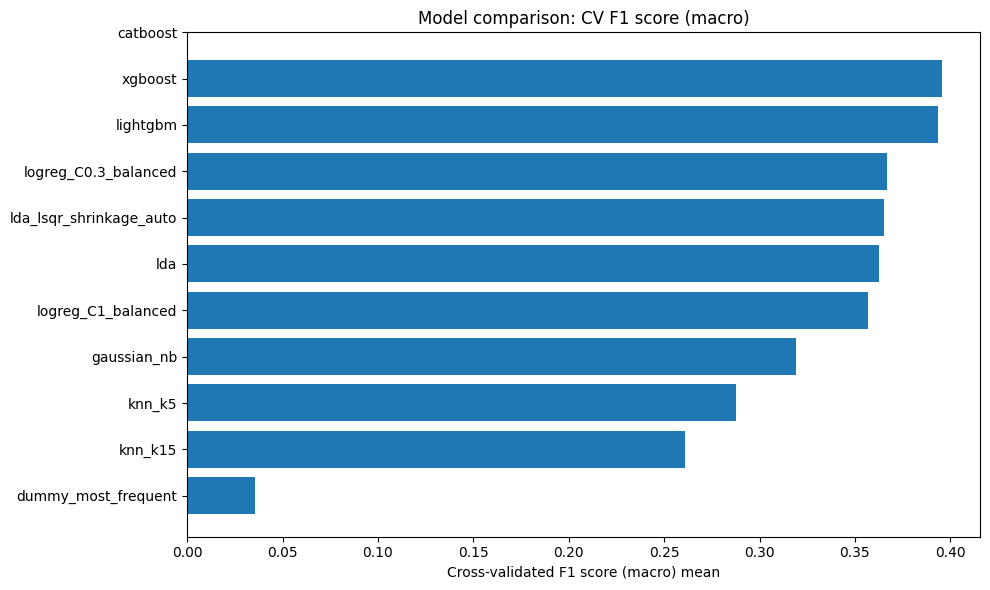

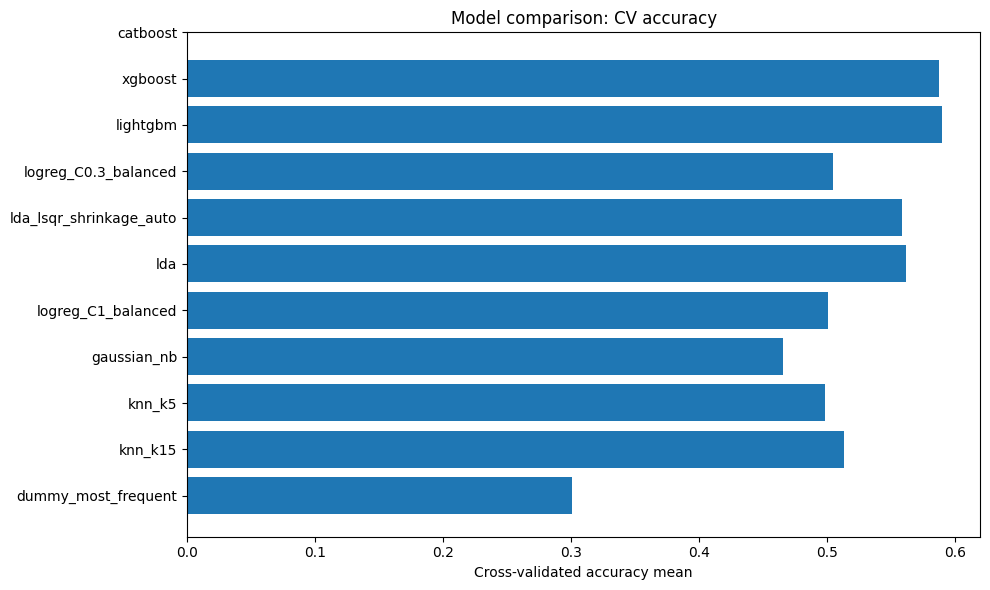

In [100]:
# ============================================================
# PLOTS: CV F1 (macro) and CV Accuracy for all models
# Assumes:
# - results_df exists and contains:
#   ["model", "f1_macro_mean", "accuracy_mean"]
# (Optional) also supports *_std columns if they exist.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ---- Safety checks ----
required_cols = {"model", "f1_macro_mean", "accuracy_mean"}
missing = required_cols - set(results_df.columns)
if missing:
    raise ValueError(f"results_df is missing required columns: {sorted(missing)}")

# Optional error bars if you have standard deviation columns
has_f1_std = "f1_macro_std" in results_df.columns
has_acc_std = "accuracy_std" in results_df.columns

# Sort for nicer plots (best at top)
plot_df = results_df.sort_values("f1_macro_mean", ascending=True).copy()

# ---- Plot 1: F1 macro (CV mean) ----
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(plot_df))

if has_f1_std:
    ax.barh(y_pos, plot_df["f1_macro_mean"].values, xerr=plot_df["f1_macro_std"].values)
else:
    ax.barh(y_pos, plot_df["f1_macro_mean"].values)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["model"].values)
ax.set_xlabel("Cross-validated F1 score (macro) mean")
ax.set_title("Model comparison: CV F1 score (macro)")
plt.tight_layout()
plt.show()

# ---- Plot 2: Accuracy (CV mean) ----
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(plot_df))

if has_acc_std:
    ax.barh(y_pos, plot_df["accuracy_mean"].values, xerr=plot_df["accuracy_std"].values)
else:
    ax.barh(y_pos, plot_df["accuracy_mean"].values)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["model"].values)
ax.set_xlabel("Cross-validated accuracy mean")
ax.set_title("Model comparison: CV accuracy")
plt.tight_layout()
plt.show()


## Diagrams

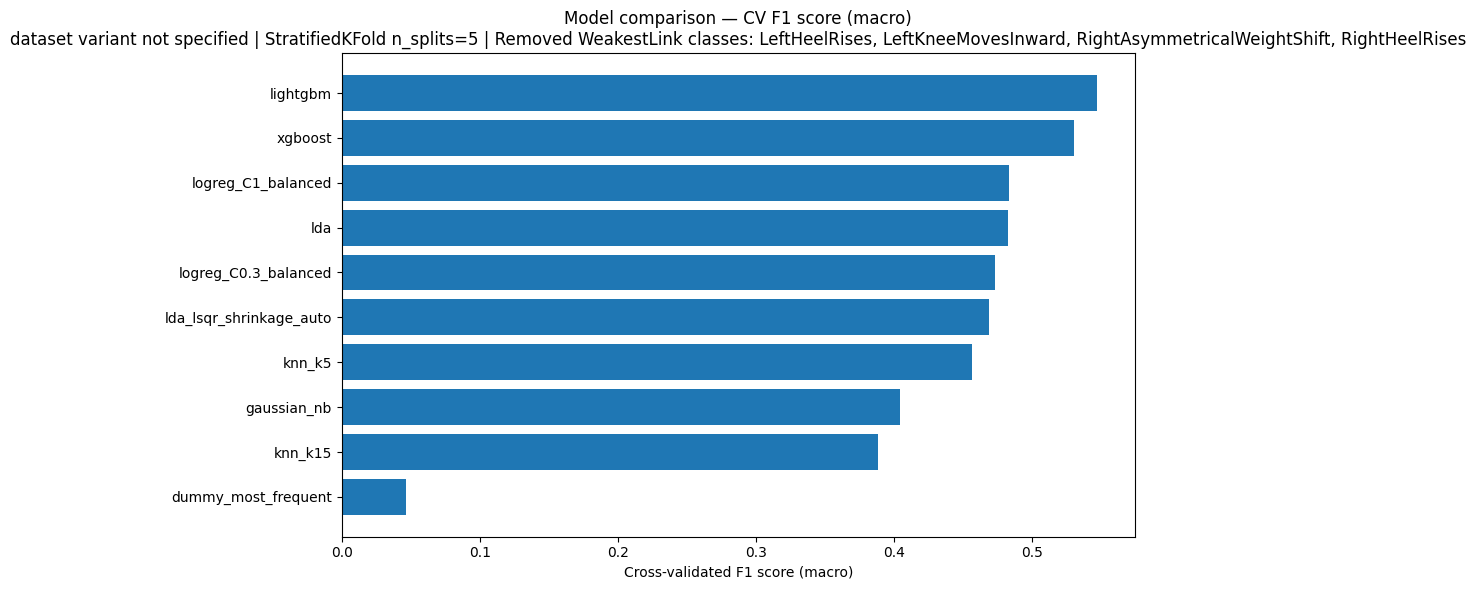

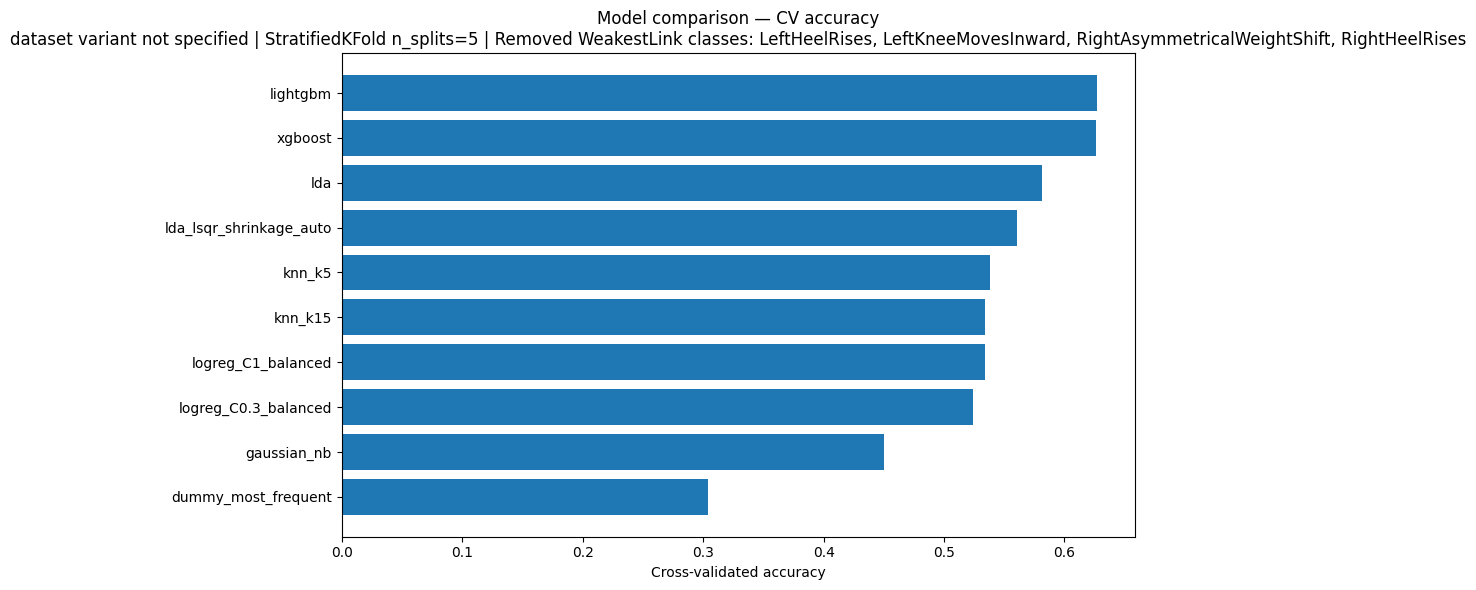

In [44]:
# ============================================================
# DIAGRAMS: CV F1 (macro) + CV Accuracy
# Title includes:
# - number of CV folds
# - whether WeakestLink classes were removed (and which ones)
#
# Assumes these already exist:
# - results_df  (columns: model, f1_macro_mean, accuracy_mean)
# - cv_splits   (int)
#
# Optional:
# - DROP_WEAK_LINKS (set of removed classes)
# - DATASET_TAG (string label for dataset variant)
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Configuration / metadata
# ------------------------------------------------------------

# Optional label to distinguish datasets in screenshots
DATASET_TAG = globals().get("DATASET_TAG", "dataset variant not specified")

# Handle the case where no WeakestLink classes were dropped
if "DROP_WEAK_LINKS" in globals() and DROP_WEAK_LINKS:
    removed_links_sorted = sorted(list(DROP_WEAK_LINKS))
    removed_links_str = ", ".join(removed_links_sorted)
    removal_text = f"Removed WeakestLink classes: {removed_links_str}"
else:
    removal_text = "Removed WeakestLink classes: None"

title_suffix = (
    f"{DATASET_TAG} | "
    f"StratifiedKFold n_splits={cv_splits} | "
    f"{removal_text}"
)

# ------------------------------------------------------------
# Prepare data for plotting
# ------------------------------------------------------------

plot_df_f1 = results_df.sort_values("f1_macro_mean", ascending=True)
plot_df_acc = results_df.sort_values("accuracy_mean", ascending=True)

# ------------------------------------------------------------
# Plot 1: CV F1 (macro)
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df_f1["model"], plot_df_f1["f1_macro_mean"])
ax.set_xlabel("Cross-validated F1 score (macro)")
ax.set_title("Model comparison — CV F1 score (macro)\n" + title_suffix)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot 2: CV Accuracy
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df_acc["model"], plot_df_acc["accuracy_mean"])
ax.set_xlabel("Cross-validated accuracy")
ax.set_title("Model comparison — CV accuracy\n" + title_suffix)
plt.tight_layout()
plt.show()
